# 05 · Interpretación, umbral, sesgo y modelo final (Producto 2)
1. Entrenamos el **modelo final** (LightGBM optimizado en `03_optimizacion.ipynb`).
2. Elegimos el **umbral de decisión** con validación cruzada (sin mirar el test).
3. Evaluamos en el test **una sola vez**.
4. ¿Qué variables pesan más? ¿El modelo trata distinto a algún grupo de edad?
5. Guardamos el modelo para la demo.

In [1]:
!pip install -q optuna lightgbm

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Datos: Bank Marketing (UCI, id 222, archivo bank-additional-full.csv), copia pública en GitHub.
# Plan B: descarguen bank-additional-full.csv desde UCI y súbanlo al panel Archivos de Colab.
URL = "https://raw.githubusercontent.com/selva86/datasets/master/bank-full.csv"

NOMBRES = {
    "age": "edad", "job": "ocupacion", "marital": "estado_civil", "education": "educacion",
    "default": "en_mora", "housing": "hipoteca", "loan": "prestamo", "contact": "tipo_contacto",
    "month": "mes", "day_of_week": "dia_semana", "duration": "duracion_llamada",
    "campaign": "contactos_campana", "pdays": "dias_ultimo_contacto", "previous": "contactos_previos",
    "poutcome": "resultado_previo", "emp.var.rate": "tasa_var_empleo", "cons.price.idx": "ipc",
    "cons.conf.idx": "confianza_consumidor", "euribor3m": "euribor3m", "nr.employed": "num_empleados"}

NUMERICAS = ["edad", "contactos_campana", "dias_ultimo_contacto", "contactos_previos",
             "tasa_var_empleo", "ipc", "confianza_consumidor", "euribor3m", "num_empleados"]
CATEGORICAS = ["ocupacion", "estado_civil", "educacion", "en_mora", "hipoteca", "prestamo",
               "tipo_contacto", "mes", "dia_semana", "resultado_previo"]
# duracion_llamada NO entra al modelo: solo se conoce DESPUÉS de la llamada (fuga de datos).

def cargar_datos():
    try:
        df = pd.read_csv(URL, sep=";")
    except Exception:
        df = pd.read_csv("bank-additional-full.csv", sep=";")
    df = df.rename(columns=NOMBRES)
    # 999 significa "nunca fue contactado": no es una cantidad, lo convertimos en faltante
    df["dias_ultimo_contacto"] = df["dias_ultimo_contacto"].replace(999, np.nan)
    df["suscribe"] = (df["y"].str.strip() == "yes").astype(int)
    return df.drop(columns="y")

df = cargar_datos()
X, y = df[NUMERICAS + CATEGORICAS], df["suscribe"]
print(df.shape, f"| suscriben: {y.mean():.1%}")

(41188, 21) | suscriben: 11.3%


In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Misma división en todos los notebooks: el test se usa una sola vez, al final
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def preprocesador():
    # add_indicator=True crea la columna "nunca fue contactado" a partir de los 999
    num = Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                    ("escalar", StandardScaler())])
    # "unknown" se mantiene como categoría propia: no saber si tiene mora también informa
    cat = Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, NUMERICAS), ("cat", cat, CATEGORICAS)])

In [4]:
from lightgbm import LGBMClassifier
# Hiperparámetros encontrados por Optuna en 03_optimizacion.ipynb (copiados de estudio.best_params)
MEJORES = {"n_estimators": 425, "learning_rate": 0.0107, "num_leaves": 34, "min_child_samples": 75,
           "subsample": 0.84, "colsample_bytree": 0.76, "reg_lambda": 0.0042, "class_weight": None}
def modelo_final():
    return Pipeline([("prep", preprocesador()),
                     ("modelo", LGBMClassifier(**MEJORES, subsample_freq=1, random_state=42, verbose=-1))])

## Umbral de decisión
Optuna eligió **no** usar `class_weight="balanced"`, así que las probabilidades están en la escala real (≈ 11 % de positivos) y el umbral 0,5 sería demasiado exigente. Tratamos el desbalance **moviendo el umbral**.

Regla de negocio: una llamada de más cuesta poco; perder un cliente que habría suscrito cuesta más. Por eso maximizamos **F2**, que pesa el recall el doble que la precisión. Usamos probabilidades de validación cruzada sobre **train**, nunca el test.

In [5]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import fbeta_score, recall_score, precision_score
prob_cv = cross_val_predict(modelo_final(), X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
filas = []
for u in np.arange(0.05, 0.55, 0.05):
    p = (prob_cv >= u).astype(int)
    filas.append({"umbral": round(u, 2), "recall": recall_score(y_tr, p), "precisión": precision_score(y_tr, p),
                  "F2": fbeta_score(y_tr, p, beta=2), "% clientes a llamar": p.mean()})
umbrales = pd.DataFrame(filas).round(3)
UMBRAL = float(umbrales.loc[umbrales["F2"].idxmax(), "umbral"])
print("Umbral elegido (máximo F2):", UMBRAL)
umbrales

Umbral elegido (máximo F2): 0.1


,umbral,recall,precisión,F2,% clientes a llamar
0,0.05,0.866,0.166,0.470,0.588
1,0.10,0.656,0.346,0.556,0.214
2,0.15,0.605,0.414,0.554,0.165
3,0.20,0.576,0.438,0.542,0.148
4,0.25,0.542,0.460,0.524,0.133
5,0.30,0.487,0.492,0.488,0.112
6,0.35,0.419,0.537,0.438,0.088
7,0.40,0.352,0.584,0.382,0.068
8,0.45,0.301,0.629,0.336,0.054
9,0.50,0.258,0.656,0.294,0.044


## Evaluación final en el test (una sola vez)

Test · PR-AUC = 0.497 · ROC-AUC = 0.818
Con umbral 0.1: recall = 0.673 · precisión = 0.369 · se llama al 21% de los clientes
Llamando solo al 10 % con mayor probabilidad: 48% de los suscriptores, tasa de éxito 54% (al azar: 11%)


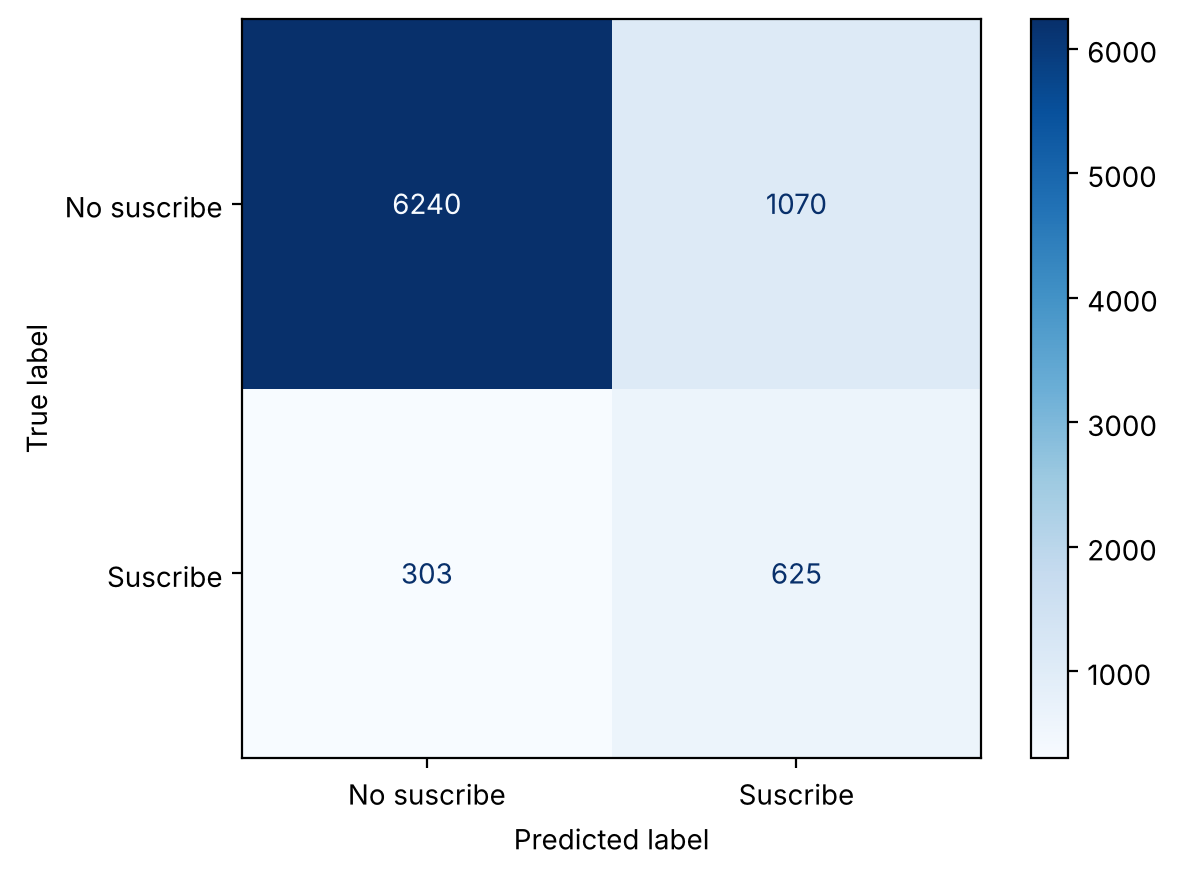

In [6]:
from sklearn.metrics import average_precision_score, roc_auc_score, ConfusionMatrixDisplay
final = modelo_final().fit(X_tr, y_tr)
prob = final.predict_proba(X_te)[:, 1]
pred = (prob >= UMBRAL).astype(int)
print(f"Test · PR-AUC = {average_precision_score(y_te, prob):.3f} · ROC-AUC = {roc_auc_score(y_te, prob):.3f}")
print(f"Con umbral {UMBRAL}: recall = {recall_score(y_te, pred):.3f} · precisión = {precision_score(y_te, pred):.3f} · "
      f"se llama al {pred.mean():.0%} de los clientes")
orden = np.argsort(-prob); top = orden[: int(0.10 * len(prob))]
print(f"Llamando solo al 10 % con mayor probabilidad: {y_te.values[top].sum() / y_te.sum():.0%} de los suscriptores, "
      f"tasa de éxito {y_te.values[top].mean():.0%} (al azar: {y_te.mean():.0%})")
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["No suscribe", "Suscribe"], cmap="Blues")
plt.show()

## ¿Qué variables pesan? Importancia por permutación en el test

num_empleados           0.093
euribor3m               0.039
dias_ultimo_contacto    0.033
tipo_contacto           0.022
resultado_previo        0.014
contactos_campana       0.010
dia_semana              0.008
ipc                     0.008
dtype: float64


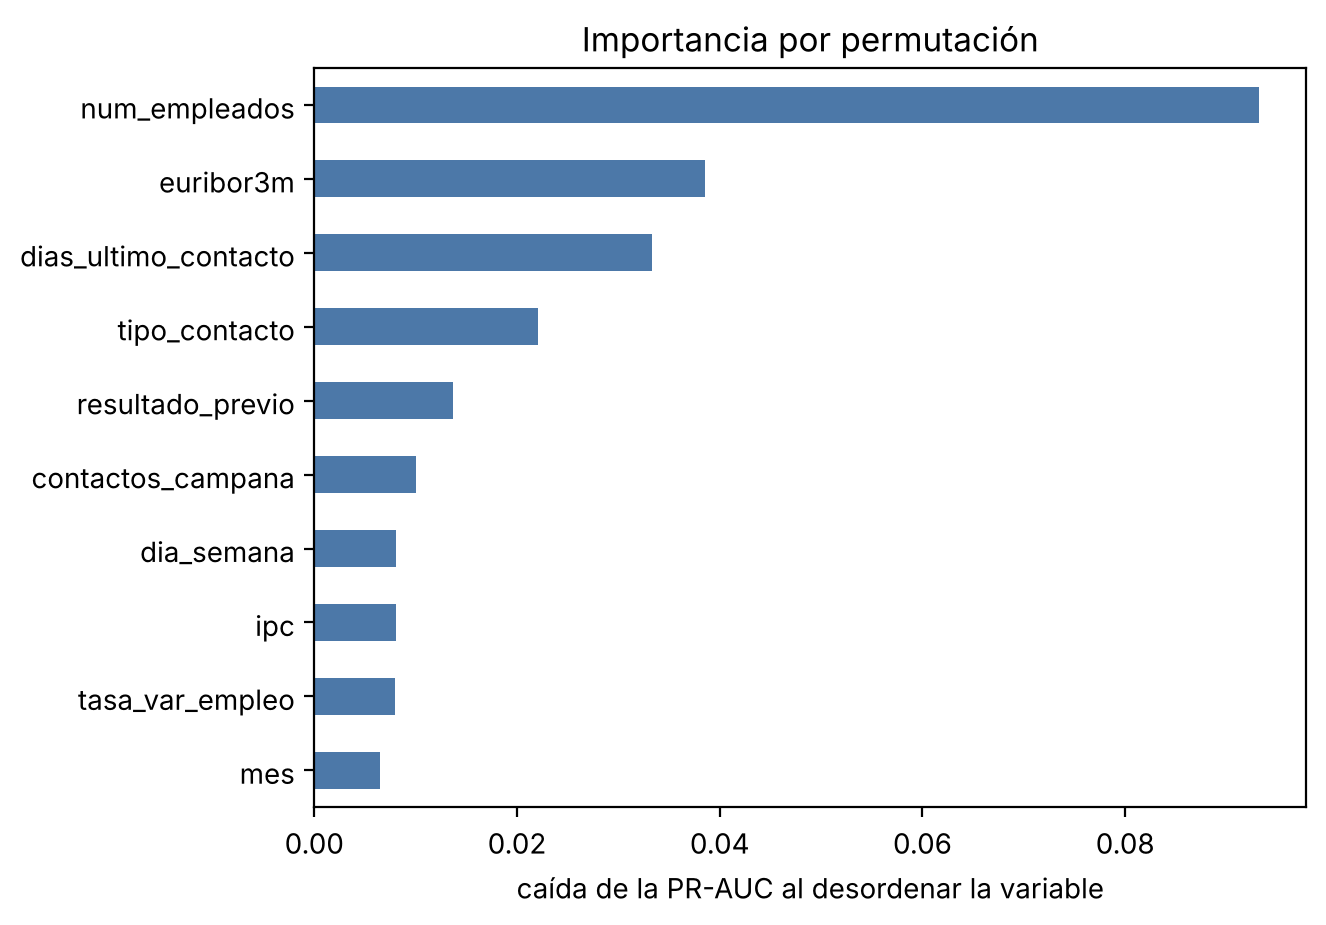

In [7]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(final, X_te, y_te, scoring="average_precision", n_repeats=5, random_state=42, n_jobs=1)
importancias = pd.Series(imp.importances_mean, index=X_te.columns).sort_values()
print(importancias.sort_values(ascending=False).head(8).round(3))
importancias.tail(10).plot.barh(color="#4C78A8")
plt.xlabel("caída de la PR-AUC al desordenar la variable"); plt.title("Importancia por permutación"); plt.show()

## Revisión de sesgo por edad
La edad es una variable sensible. ¿El modelo detecta igual de bien a los clientes interesados en cada grupo?

In [8]:
grupo_edad = pd.cut(X_te["edad"], [0, 25, 60, 120], labels=["≤ 25", "26–60", "> 60"])
filas = []
for g in grupo_edad.cat.categories:
    m = (grupo_edad == g).values
    filas.append({"grupo": g, "clientes": m.sum(), "tasa real": y_te.values[m].mean(),
                  "% llamados": pred[m].mean(),
                  "recall": recall_score(y_te.values[m], pred[m]),
                  "precisión": precision_score(y_te.values[m], pred[m], zero_division=0)})
pd.DataFrame(filas).round(3)

,grupo,clientes,tasa real,% llamados,recall,precisión
0,≤ 25,320,0.216,0.494,0.913,0.399
1,26–60,7734,0.100,0.175,0.617,0.353
2,> 60,184,0.457,1.000,1.000,0.457


In [9]:
filas = []
for g in ["married", "single", "divorced"]:
    m = (X_te["estado_civil"] == g).values
    filas.append({"estado civil": g, "clientes": m.sum(), "tasa real": y_te.values[m].mean(),
                  "recall": recall_score(y_te.values[m], pred[m]),
                  "precisión": precision_score(y_te.values[m], pred[m], zero_division=0)})
pd.DataFrame(filas).round(3)

,estado civil,clientes,tasa real,recall,precisión
0,married,4975,0.103,0.660,0.389
1,single,2311,0.134,0.729,0.350
2,divorced,937,0.112,0.581,0.345


## Prueba de estrés: ¿y si el futuro no se parece al pasado?
Las filas del archivo están ordenadas en el tiempo (mayo 2008 – noviembre 2010). La división aleatoria mezcla meses, así que el test "ya conoce" el contexto económico. Aquí entrenamos con el **primer 80 %** de las filas y probamos con el **último 20 %**. Es solo un diagnóstico de limitaciones: no cambia la elección del modelo.

In [10]:
corte = int(0.8 * len(X))
temporal = modelo_final().fit(X.iloc[:corte], y.iloc[:corte])
p_tmp = temporal.predict_proba(X.iloc[corte:])[:, 1]
base_tr, base_te = y.iloc[:corte].mean(), y.iloc[corte:].mean()
pr = average_precision_score(y.iloc[corte:], p_tmp)
print(f"Tasa de suscripción · primer 80 %: {base_tr:.1%} · último 20 %: {base_te:.1%}")
print(f"PR-AUC temporal = {pr:.3f} (al azar: {base_te:.3f}) → {pr / base_te:.1f} veces mejor que el azar")
print(f"PR-AUC aleatoria = {average_precision_score(y_te, prob):.3f} (al azar: {y_te.mean():.3f}) → "
      f"{average_precision_score(y_te, prob) / y_te.mean():.1f} veces mejor que el azar")

Tasa de suscripción · primer 80 %: 6.4% · último 20 %: 30.8%
PR-AUC temporal = 0.488 (al azar: 0.308) → 1.6 veces mejor que el azar
PR-AUC aleatoria = 0.497 (al azar: 0.113) → 4.4 veces mejor que el azar


## Guardar el modelo final para la demo

In [11]:
import joblib
from pathlib import Path
destino = Path("../app") if Path("../app").exists() else Path(".")
# Se reentrena con TODOS los datos (train + test) solo para producción; las métricas reportadas son las del test.
produccion = modelo_final().fit(X, y)
joblib.dump({"modelo": produccion, "umbral": UMBRAL}, destino / "modelo.joblib")
print("Guardado en", (destino / "modelo.joblib").resolve())

Guardado en /home/claude/repo/app/modelo.joblib


## Conclusión
- **Test:** PR-AUC = 0,497 y ROC-AUC = 0,818. Con el umbral 0,10 se llama al 21 % de los clientes y se detecta el **67 %** de los que suscriben (precisión 37 %, tres veces la tasa al azar).
- **Variables que pesan:** el contexto económico (`num_empleados`, `euribor3m`) domina, seguido del historial con el cliente (`dias_ultimo_contacto`, `resultado_previo`) y el canal (`tipo_contacto`).
- **Sesgo por edad:** el modelo marca al **100 %** de los mayores de 60 años. Su tasa real es alta (46 %), pero en la práctica significa insistir con productos financieros a personas mayores, un grupo que puede ser vulnerable a la venta presionada. Recomendamos un tope de llamadas y un guion específico para este grupo.
- **Limitación principal:** con una división temporal, el modelo es solo 1,6 veces mejor que el azar (frente a 4,4 veces con la división aleatoria). El modelo aprende mucho del *momento económico*; antes de usarlo habría que reentrenarlo con datos recientes y validarlo en el tiempo.